<a href="https://colab.research.google.com/github/Fsrkh/Water-Quality-project/blob/main/Water_Quality_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# River water quality across seasons and sections

How do oxygen and nitrate concentrations differ between spring and autumn? How do their means change from the headwaters to the mouth when all four seasons receive equal weight?

In the original sample, mean nitrate was higher in spring by 0.871 mg/L and increased at each successive river section. The estimated spring–autumn oxygen difference was smaller, and its confidence interval included zero.


## 1. Data and sampling design

Each row records one sample ID, a river section, a season (`saison`), and two concentrations measured in mg/L.

In [ ]:
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from IPython.display import display

path = Path("waterquality.csv")
if not path.is_file():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f"Place {path.name} in {Path.cwd()} and rerun this cell.") from None
    print("Select the original waterquality.csv file.")
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("Select one water-quality CSV file.")
    path = Path(next(iter(uploaded)))

In [ ]:
df = pd.read_csv(path, sep=";", decimal=".", encoding="utf-8-sig")

display(df.head())
df.info()

,ID,river_section,saison,nitrate_mgL,oxygen_mgL
0,1,A1_headwaters,spring,5.540,10.711
1,2,A1_headwaters,spring,3.328,9.937
2,3,A1_headwaters,spring,5.742,10.499
3,4,A1_headwaters,spring,7.822,10.405
4,5,A1_headwaters,spring,8.843,10.245


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             900 non-null    int64  
 1   river_section  900 non-null    object 
 2   saison         900 non-null    object 
 3   nitrate_mgL    900 non-null    float64
 4   oxygen_mgL     900 non-null    float64
dtypes: float64(2), int64(1), object(2)
memory usage: 35.3+ KB


In [ ]:
print("Total rows:", len(df))
print("Distinct non-missing IDs:", df["ID"].nunique())
print("Missing IDs:", df["ID"].isna().sum())

# Show where repeated IDs occur, if there are any.
repeated_id = df["ID"].notna() & df["ID"].duplicated(keep=False)
display(
    df.loc[repeated_id, ["ID", "river_section", "saison"]]
    .sort_values(["ID", "saison"])
    .head(12)
)

# Check that both concentration measurements are present across all four seasons.
display(df[["oxygen_mgL", "nitrate_mgL"]].isna().sum().rename("missing_values"))

Total rows: 900
Distinct non-missing IDs: 900
Missing IDs: 0


,ID,river_section,saison


,missing_values
oxygen_mgL,0
nitrate_mgL,0


In [ ]:
display(pd.crosstab(df["river_section"], df["saison"], margins=True))

saison,autumn,spring,summer,winter,All
river_section,,,,,
A1_headwaters,45,45,45,45,180
A2_upper_course,45,45,45,45,180
A3_middle_course,45,45,45,45,180
A4_lower_course,45,45,45,45,180
A5_mouth,45,45,45,45,180
All,225,225,225,225,900


The original file contains 900 distinct sample IDs and 45 observations per section and season. Unique IDs identify rows. The file provides no dates or individual site identifiers for assessing repeated sampling.

## 2. Seasonal patterns

The summary gives the sample count, mean, median and standard deviation for each substance. All differences in this section use spring minus autumn.

In [ ]:
seasonal_summary = (
    df.loc[df["saison"].isin(["spring", "autumn"])]
    .groupby("saison")[["oxygen_mgL", "nitrate_mgL"]]
    .agg(["count", "mean", "median", "std"])
    .reindex(["spring", "autumn"])
)

display(seasonal_summary.round(2))

oxygen_mgL                    nitrate_mgL                   
            count  mean median   std       count  mean median   std
saison                                                             
spring        225  9.53   9.55  0.86         225  9.29   9.65  2.59
autumn        225  9.38   9.51  0.89         225  8.42   8.57  2.75

In [ ]:
means = df.groupby("saison")[["oxygen_mgL", "nitrate_mgL"]].mean()
display((means.loc["spring"] - means.loc["autumn"]).round(2))

,0
oxygen_mgL,0.15
nitrate_mgL,0.87


In [ ]:
spring_autumn = df[df["saison"].isin(["spring", "autumn"])]

section_means = spring_autumn.groupby(["river_section", "saison"])[
    ["oxygen_mgL", "nitrate_mgL"]
].mean()

spring = section_means.xs("spring", level="saison")
autumn = section_means.xs("autumn", level="saison")

section_differences = spring - autumn
display(section_differences.round(2))

,oxygen_mgL,nitrate_mgL
river_section,,
A1_headwaters,0.28,0.93
A2_upper_course,0.14,1.19
A3_middle_course,0.00,0.67
A4_lower_course,0.38,1.00
A5_mouth,-0.05,0.56


In [ ]:
nitrate = section_differences["nitrate_mgL"]
print(f"Largest nitrate difference: {nitrate.idxmax()}, {nitrate.max():.2f} mg/L")

mouth_oxygen = section_differences.loc["A5_mouth", "oxygen_mgL"]
print(f"Oxygen at the mouth (spring minus autumn): {mouth_oxygen:.2f} mg/L")

Largest nitrate difference: A2_upper_course, 1.19 mg/L
Oxygen at the mouth (spring minus autumn): -0.05 mg/L


### Figure 1. Oxygen and nitrate distributions by section and season

The line inside each box marks the median. The box spans the middle 50% of observations.

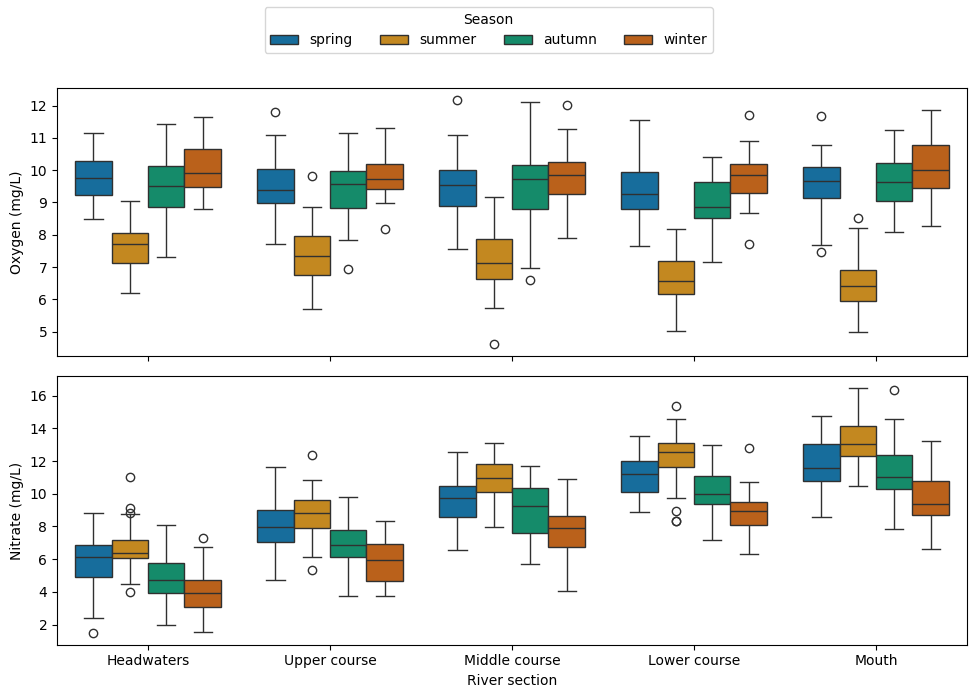

In [ ]:
section_order = [
    "A1_headwaters", "A2_upper_course", "A3_middle_course",
    "A4_lower_course", "A5_mouth"
]
section_labels = ["Headwaters", "Upper course", "Middle course", "Lower course", "Mouth"]
season_order = ["spring", "summer", "autumn", "winter"]

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

for ax, (column, label) in zip(
    axes, [("oxygen_mgL", "Oxygen"), ("nitrate_mgL", "Nitrate")]
):
    sns.boxplot(
        data=df,
        x="river_section",
        y=column,
        hue="saison",
        order=section_order,
        hue_order=season_order,
        palette="colorblind",
        ax=ax
    )
    ax.set_ylabel(f"{label} (mg/L)")
    ax.set_xlabel("")
    ax.legend_.remove()

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Season", loc="upper center", ncol=4)
axes[1].set_xticks(range(len(section_labels)), labels=section_labels)
axes[1].set_xlabel("River section")
fig.tight_layout(rect=[0, 0, 1, 0.90])
fig.savefig("figure_1_water_quality.png", dpi=300, bbox_inches="tight")
plt.show()

### Oxygen at the mouth

The seasonal means and medians give slightly different descriptions here. The spring mean is about 0.046 mg/L lower and the spring median is 0.017 mg/L higher than in autumn.

In [ ]:
mouth = df.loc[df["river_section"] == "A5_mouth"]
mouth_oxygen = (
    mouth.groupby("saison")["oxygen_mgL"]
    .agg(["mean", "median"])
    .loc[["spring", "autumn"]]
)

display(mouth_oxygen)

,mean,median
saison,,
spring,9.536533,9.651
autumn,9.582689,9.634


### Spring nitrate at the headwaters and mouth

The interquartile range (IQR) is the difference between the third and first quartiles, in mg/L.

In [ ]:
spring = df.loc[df["saison"] == "spring"]

quartiles = (
    spring.groupby("river_section")["nitrate_mgL"]
    .quantile([0.25, 0.50, 0.75])
    .unstack()
    .rename(columns={0.25: "Q1", 0.50: "Median", 0.75: "Q3"})
)

quartiles["IQR"] = quartiles["Q3"] - quartiles["Q1"]
display(quartiles.loc[["A1_headwaters", "A5_mouth"]].round(2))

,Q1,Median,Q3,IQR
river_section,,,,
A1_headwaters,4.91,6.14,6.87,1.96
A5_mouth,10.81,11.58,13.06,2.25


## 3. Spring–autumn mean differences

Each model includes a season indicator and its interaction with river section. Sum coding gives each section equal weight in the seasonal estimate. The models use HC3 standard errors, two-sided tests and 95% confidence intervals. Inference assumes independent observations.

In [ ]:
season_data = df.loc[df["saison"].isin(["spring", "autumn"])].copy()
season_data["is_spring"] = (season_data["saison"] == "spring").astype(int)

oxygen_model = smf.ols(
    "oxygen_mgL ~ is_spring * C(river_section, Sum)",
    data=season_data
).fit(cov_type="HC3", use_t=True)

difference = oxygen_model.params["is_spring"]
lower, upper = oxygen_model.conf_int().loc["is_spring"]
p_value = oxygen_model.pvalues["is_spring"]

print(f"Mean difference (spring − autumn): {difference:.3f} mg/L")
print(f"95% confidence interval: [{lower:.3f}, {upper:.3f}] mg/L")
print(f"Two-sided p-value: {p_value:.4g}")

Mean difference (spring − autumn): 0.152 mg/L
95% confidence interval: [-0.010, 0.314] mg/L
Two-sided p-value: 0.06539


In [ ]:
nitrate_model = smf.ols(
    "nitrate_mgL ~ is_spring * C(river_section, Sum)",
    data=season_data
).fit(cov_type="HC3", use_t=True)

difference = nitrate_model.params["is_spring"]
lower, upper = nitrate_model.conf_int().loc["is_spring"]
p_value = nitrate_model.pvalues["is_spring"]

print(f"Mean nitrate difference (spring − autumn): {difference:.3f} mg/L")
print(f"95% confidence interval: [{lower:.3f}, {upper:.3f}] mg/L")
print(f"Two-sided p-value: {p_value:.4g}")

Mean nitrate difference (spring − autumn): 0.871 mg/L
95% confidence interval: [0.592, 1.149] mg/L
Two-sided p-value: 1.817e-09


### Check the nitrate estimate against the sample means

Equal sample counts across sections make the overall difference in sample means equal to the model estimate.

In [ ]:
season_means = season_data.groupby("saison")["nitrate_mgL"].mean()
print(f"Spring mean:   {season_means['spring']:.3f} mg/L")
print(f"Autumn mean:   {season_means['autumn']:.3f} mg/L")
print(f"Spring − autumn: {season_means['spring'] - season_means['autumn']:.3f} mg/L")
print(f"Model estimate:  {nitrate_model.params['is_spring']:.3f} mg/L")

Spring mean:   9.289 mg/L
Autumn mean:   8.418 mg/L
Spring − autumn: 0.871 mg/L
Model estimate:  0.871 mg/L


### Figure 2. Seasonal mean differences with 95% confidence intervals

The dashed line marks a difference of zero. The nitrate interval lies above zero. For oxygen, the interval extends from −0.010 to 0.314 mg/L.

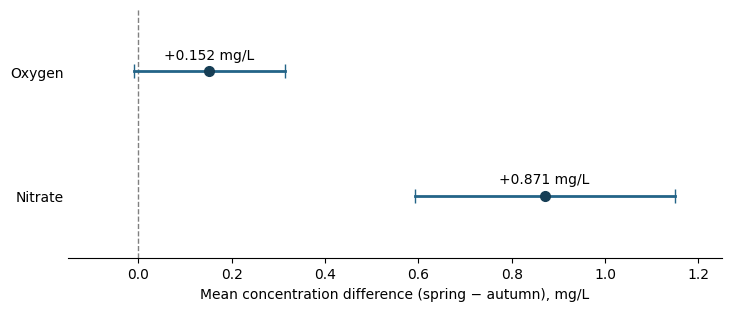

In [ ]:
fig, ax = plt.subplots(figsize=(7.2, 3.0), constrained_layout=True)

for y, (label, model) in enumerate([
    ("Oxygen", oxygen_model),
    ("Nitrate", nitrate_model),
]):
    estimate = model.params["is_spring"]
    lower, upper = model.conf_int().loc["is_spring"]

    ax.plot([lower, upper], [y, y], color="#236487", linewidth=2)
    ax.plot([lower, upper], [y, y], "|", color="#236487", markersize=10)
    ax.plot(estimate, y, "o", color="#163e55", markersize=7)

    ax.annotate(
        f"{estimate:+.3f} mg/L",
        (estimate, y),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
    )

ax.axvline(0, color="gray", linestyle="--", linewidth=1, zorder=0)
ax.set_yticks([0, 1], labels=["Oxygen", "Nitrate"])
ax.set_ylim(1.5, -0.5)
ax.set_xlim(-0.15, 1.25)
ax.set_xlabel("Mean concentration difference (spring − autumn), mg/L")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)

fig.savefig("figure_2_seasonal_differences.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Differences along the river

First calculate the mean in each section and season, then average those four seasonal means within each section. The endpoint comparison uses mouth minus headwaters.

In [ ]:
concentrations = ["oxygen_mgL", "nitrate_mgL"]

seasonal_means = df.groupby(["river_section", "saison"])[concentrations].mean()
section_means = seasonal_means.groupby("river_section").mean()

display(section_means.round(3))

mouth_minus_headwaters = (
    section_means.loc["A5_mouth"] - section_means.loc["A1_headwaters"]
)
print("Mouth minus headwaters (mg/L)")
display(mouth_minus_headwaters.round(3))

,oxygen_mgL,nitrate_mgL
river_section,,
A1_headwaters,9.231,5.350
A2_upper_course,9.005,7.343
A3_middle_course,8.990,9.328
A4_lower_course,8.694,10.570
A5_mouth,8.936,11.467


Mouth minus headwaters (mg/L)


,0
oxygen_mgL,-0.294
nitrate_mgL,6.116


### Overall test for each substance

The section-by-season model allows the spatial pattern to vary with season. The joint F-test asks whether the five section means, averaged equally over seasons, are equal.

In [ ]:
section_models = {}

for outcome in ["oxygen_mgL", "nitrate_mgL"]:
    model = smf.ols(
        f"{outcome} ~ C(river_section, Sum) * C(saison, Sum)",
        data=df
    ).fit(cov_type="HC3", use_t=True)

    section_models[outcome] = model
    tests = model.wald_test_terms(scalar=True).table
    section_test = tests.loc["C(river_section, Sum)"]

    print(
        f"{outcome}: F = {section_test['statistic']:.3f}, "
        f"p = {section_test['pvalue']:.4g}"
    )

oxygen_mgL: F = 10.676, p = 1.883e-08
nitrate_mgL: F = 528.052, p = 4.262e-232


### Pairwise comparisons

Each estimate uses downstream minus upstream in mg/L. A positive value means the downstream section had the higher seasonal-average concentration. Holm adjustment covers the ten comparisons within each substance.

In [ ]:
def design_rows(model, grid):
    """Build design-matrix rows for new data using the fitted model's formula info."""
    from patsy import build_design_matrices

    data = model.model.data
    info = getattr(data, "design_info", None)
    if info is None:
        info = getattr(data, "model_spec", None)
    if info is None:
        raise AttributeError("Could not find the formula design info on the fitted model")

    if hasattr(info, "get_model_matrix"):
        return np.asarray(info.get_model_matrix(grid))
    return np.asarray(build_design_matrices([info], grid)[0])


results = []

for outcome, model in section_models.items():
    section_weights = {}

    for section in section_order:
        grid = pd.DataFrame({"river_section": section, "saison": season_order})
        section_weights[section] = design_rows(model, grid).mean(axis=0)

    for upstream, downstream in combinations(section_order, 2):
        contrast = section_weights[downstream] - section_weights[upstream]
        test = model.t_test(contrast)

        results.append({
            "substance": outcome,
            "upstream": upstream,
            "downstream": downstream,
            "difference_mgL": np.asarray(test.effect).item(),
            "p_raw": np.asarray(test.pvalue).item(),
        })

pairwise = pd.DataFrame(results)

# Apply Holm's adjustment to the 10 comparisons within each substance.
pairwise["p_holm"] = pairwise.groupby("substance")["p_raw"].transform(
    lambda p: multipletests(p, method="holm")[1]
)
pairwise["significant"] = pairwise["p_holm"] <= 0.05

display(pairwise.style.format({
    "difference_mgL": "{:+.3f}",
    "p_raw": "{:.3g}",
    "p_holm": "{:.3g}",
}))

,substance,upstream,downstream,difference_mgL,p_raw,p_holm,significant
0,oxygen_mgL,A1_headwaters,A2_upper_course,-0.226,0.00819,0.0403,True
1,oxygen_mgL,A1_headwaters,A3_middle_course,-0.241,0.00805,0.0403,True
2,oxygen_mgL,A1_headwaters,A4_lower_course,-0.537,1.48e-10,1.48e-09,True
3,oxygen_mgL,A1_headwaters,A5_mouth,-0.294,0.000621,0.00497,True
4,oxygen_mgL,A2_upper_course,A3_middle_course,-0.015,0.87,1,False
5,oxygen_mgL,A2_upper_course,A4_lower_course,-0.311,0.000335,0.00302,True
6,oxygen_mgL,A2_upper_course,A5_mouth,-0.069,0.442,1,False
7,oxygen_mgL,A3_middle_course,A4_lower_course,-0.296,0.00135,0.00947,True
8,oxygen_mgL,A3_middle_course,A5_mouth,-0.053,0.575,1,False
9,oxygen_mgL,A4_lower_course,A5_mouth,+0.243,0.00537,0.0322,True


## 5. Interpretation

Across the four seasons, mean nitrate rose by 6.116 mg/L from the headwaters to the mouth. The increase between neighbouring sections ranged from 1.993 mg/L at the upstream end to 0.897 mg/L at the downstream end. Mean oxygen was highest at the headwaters and lowest in the lower course, then rose by 0.243 mg/L at the mouth.

The balanced design gives every section and season equal representation. If some samples came from repeated visits to the same site, their concentrations could be correlated. The available sampling information limits how precisely the uncertainty in these comparisons can be assessed.